# EDA:

This notebook reads the two caches the forecast is built from, looks at how each variable is distributed, and joins them into `model_df`. That table is what a later OpenSTEF model trains on. The script `src/build_load_area_frame.py` writes the same join to `data/processed/load_area_hourly.parquet`.

The grain is one PJM **load area** (a metered distribution company) per hour. Zone, market region, and full PJM are sums of those areas. OpenSTEF reads `timestamp` (US/Eastern hour beginning) as the index and `load` (MW) as the target. It builds lags and calendar features itself, so those columns are left out of `model_df`.

1. Load the caches and see the structure.
2. Look at the distribution of load and of weather.
3. Inner-join on `(timestamp_utc, load_area)` and inspect `model_df`.

In [3]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch

def repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find pyproject.toml. Open this notebook from the forecast-energy repo."
    )

ROOT = repo_root()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from build_load_area_frame import read_archive_weather, read_load_cache
from pjm_forecasting.areas import LOAD_AREAS
from pjm_forecasting.frame import JOIN_KEYS, build_load_area_frame
from pjm_forecasting.ingest.pjm import rollup_load
from pjm_forecasting.schema import FRAME_COLUMNS, WEATHER_COLUMNS

LOAD_ROOT = ROOT / "data" / "raw" / "pjm"
WEATHER_ROOT = ROOT / "data" / "raw" / "openmeteo" / "load_areas"
CATALOG_ORDER = [area.code for area in LOAD_AREAS]
REGION_COLOR = {"MIDATL": "#1f77b4", "WEST": "#ff7f0e", "SOUTH": "#2ca02c"}

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.rcParams.update({"axes.grid": True, "axes.axisbelow": True, "figure.dpi": 110})


def hour_coverage(frame: pd.DataFrame) -> pd.DataFrame:
    """Hours present versus the continuous UTC span from first to last hour."""
    rows = []
    for area, part in frame.groupby("load_area", sort=False):
        start = part["timestamp_utc"].min()
        end = part["timestamp_utc"].max()
        expected = int((end - start) / pd.Timedelta(hours=1)) + 1
        actual = int(part["timestamp_utc"].nunique())
        rows.append(
            {
                "load_area": area,
                "start_utc": start,
                "end_utc": end,
                "hours": actual,
                "missing_hours": expected - actual,
            }
        )
    out = pd.DataFrame(rows)
    out["load_area"] = pd.Categorical(out["load_area"], CATALOG_ORDER, ordered=True)
    return out.sort_values("load_area").reset_index(drop=True)


def catalog_gap(frame: pd.DataFrame, name: str) -> None:
    cached = set(frame["load_area"].astype(str).unique())
    catalog = set(CATALOG_ORDER)
    print(f"{name}: {len(cached)} load areas, {len(frame):,} rows")
    print("  in the catalog, absent from this cache:", sorted(catalog - cached) or "none")
    print("  in this cache, absent from the catalog:", sorted(cached - catalog) or "none")

## 1. Load the caches

Metered load is one parquet per load area per month under `data/raw/pjm/load_areas/{LOAD_AREA}/`. Archive weather is one parquet per load area under `data/raw/openmeteo/load_areas/{LOAD_AREA}/`. Files named `forecast_*.parquet` are the live horizon and are skipped here.

Both readers stack those files and keep the last row when `(timestamp_utc, load_area)` is repeated.

In [4]:
load_files = sorted((LOAD_ROOT / "load_areas").glob("*/*.parquet"))
weather_files = sorted(
    path
    for path in WEATHER_ROOT.glob("*/*.parquet")
    if not path.name.startswith("forecast_")
)
print(f"{len(load_files)} monthly load files")
print(f"{len(weather_files)} archive weather files")

load = read_load_cache(LOAD_ROOT)
weather = read_archive_weather(WEATHER_ROOT)

catalog_gap(load, "load")
catalog_gap(weather, "weather")
print(f"load memory: {load.memory_usage(deep=True).sum() / 1e6:.0f} MB")
print(f"weather memory: {weather.memory_usage(deep=True).sum() / 1e6:.0f} MB")

3074 monthly load files
30 archive weather files
load: 29 load areas, 2,221,223 rows
  in the catalog, absent from this cache: none
  in this cache, absent from the catalog: none
weather: 29 load areas, 2,227,867 rows
  in the catalog, absent from this cache: none
  in this cache, absent from the catalog: none
load memory: 132 MB
weather memory: 169 MB


### Load structure

Each row is one metered hour for one distribution company. `timestamp` is the US/Eastern hour beginning. `timestamp_utc` is the same instant. On the autumn fall-back, the Eastern wall clock repeats and both instants stay in the table, distinguished by `timestamp_utc`.

`missing_hours` is the gap between the first and last UTC hour of that area. An area PJM had not published yet starts later, so a late start is a shorter span, and a gap inside the span shows up here. Hours stored as 0 MW are listed after the coverage table.

In [5]:
print(load.dtypes.to_string())
display(load.head(3))

print("zones:", ", ".join(sorted(load["zone"].unique())))
print("market regions:", ", ".join(sorted(load["mkt_region"].unique())))
print(
    "duplicate (timestamp_utc, load_area) rows:",
    int(load.duplicated(JOIN_KEYS).sum()),
)
print("null load rows:", int(load["load"].isna().sum()))
print("nonpositive load rows:", int((load["load"] <= 0).sum()))
display(
    load.loc[load["load"] <= 0, ["timestamp", "timestamp_utc", "load_area", "zone", "load"]]
    .sort_values(["load_area", "timestamp_utc"])
    .reset_index(drop=True)
)

wall = load["load_area"].astype(str) + "|" + load["timestamp"].dt.strftime("%Y-%m-%d %H:%M")
repeated = wall.duplicated(keep=False)
print(f"rows on a repeated US/Eastern wall-clock hour: {int(repeated.sum())}")
display(
    load.loc[repeated, ["timestamp", "timestamp_utc", "load_area", "zone", "load"]]
    .sort_values(["load_area", "timestamp_utc"])
    .head(4)
)

load_coverage = hour_coverage(load)
display(load_coverage)
print("areas with a gap inside their span:")
display(load_coverage.loc[load_coverage["missing_hours"] > 0])

timestamp        datetime64[us, US/Eastern]
timestamp_utc           datetime64[us, UTC]
load_area                               str
zone                                    str
mkt_region                              str
load                                float64


,timestamp,timestamp_utc,load_area,zone,mkt_region,load
0,2018-01-01 00:00:00-05:00,2018-01-01 05:00:00+00:00,AECO,AE,MIDATL,1261.317
1,2018-01-01 01:00:00-05:00,2018-01-01 06:00:00+00:00,AECO,AE,MIDATL,1221.330
2,2018-01-01 02:00:00-05:00,2018-01-01 07:00:00+00:00,AECO,AE,MIDATL,1190.517


zones: AE, AEP, AP, ATSI, BC, CE, DAY, DEOK, DOM, DPL, DUQ, EKPC, JC, ME, OVEC, PE, PEP, PL, PN, PS, RECO
market regions: MIDATL, SOUTH, WEST
duplicate (timestamp_utc, load_area) rows: 0
null load rows: 0
nonpositive load rows: 18


,timestamp,timestamp_utc,load_area,zone,load
0,2020-03-08 01:00:00-05:00,2020-03-08 06:00:00+00:00,AECO,AE,0.0
1,2021-03-14 01:00:00-05:00,2021-03-14 06:00:00+00:00,AECO,AE,0.0
2,2023-03-12 01:00:00-05:00,2023-03-12 06:00:00+00:00,AECO,AE,0.0
3,2024-03-10 01:00:00-05:00,2024-03-10 06:00:00+00:00,AECO,AE,0.0
4,2025-03-09 01:00:00-05:00,2025-03-09 06:00:00+00:00,AECO,AE,0.0
5,2026-03-08 01:00:00-05:00,2026-03-08 06:00:00+00:00,AECO,AE,0.0
6,2020-03-08 01:00:00-05:00,2020-03-08 06:00:00+00:00,DPLCO,DPL,0.0
7,2021-03-14 01:00:00-05:00,2021-03-14 06:00:00+00:00,DPLCO,DPL,0.0
8,2023-03-12 01:00:00-05:00,2023-03-12 06:00:00+00:00,DPLCO,DPL,0.0
9,2024-03-10 01:00:00-05:00,2024-03-10 06:00:00+00:00,DPLCO,DPL,0.0


rows on a repeated US/Eastern wall-clock hour: 462


,timestamp,timestamp_utc,load_area,zone,load
7368,2018-11-04 01:00:00-04:00,2018-11-04 05:00:00+00:00,AECO,AE,773.694
7369,2018-11-04 01:00:00-05:00,2018-11-04 06:00:00+00:00,AECO,AE,743.987
16104,2019-11-03 01:00:00-04:00,2019-11-03 05:00:00+00:00,AECO,AE,787.491
16105,2019-11-03 01:00:00-05:00,2019-11-03 06:00:00+00:00,AECO,AE,766.030


,load_area,start_utc,end_utc,hours,missing_hours
0,AECO,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0
1,VMEU,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0
2,BC,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0
3,DPLCO,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0
4,EASTON,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0
5,JC,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0
6,ME,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0
7,PE,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0
8,PEPCO,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0
9,SMECO,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76871,0


areas with a gap inside their span:


,load_area,start_utc,end_utc,hours,missing_hours
18,AEPOPT,2018-01-01 05:00:00+00:00,2026-10-09 03:00:00+00:00,76851,20


### Weather structure

Each load area is one city in the catalog. The archive API returns the same five hourly variables the forecast API will return later: temperature (°C), relative humidity (%), wind speed at 10 m (m/s), shortwave radiation (W/m²), and surface pressure (hPa). Archive hours are reanalysis.

In [6]:
print(weather.dtypes.to_string())
display(weather.head(3))
print(
    "duplicate (timestamp_utc, load_area) rows:",
    int(weather.duplicated(JOIN_KEYS).sum()),
)
print("nulls per column:")
display(weather[list(WEATHER_COLUMNS)].isna().sum())

bounds = {
    "temperature_2m": (-50, 50),
    "relative_humidity_2m": (0, 100),
    "wind_speed_10m": (0, 60),
    "shortwave_radiation": (0, 1400),
    "surface_pressure": (900, 1100),
}
outside = []
for column, (low, high) in bounds.items():
    values = weather[column]
    mask = values.notna() & ((values < low) | (values > high))
    outside.append(
        {
            "column": column,
            "min": values.min(),
            "max": values.max(),
            "outside_bounds": int(mask.sum()),
        }
    )
display(pd.DataFrame(outside))

weather_coverage = hour_coverage(weather)
display(weather_coverage)
print("areas with a gap inside their span:")
display(weather_coverage.loc[weather_coverage["missing_hours"] > 0])

timestamp               datetime64[us, US/Eastern]
timestamp_utc                  datetime64[us, UTC]
load_area                                      str
temperature_2m                             float64
relative_humidity_2m                         int64
wind_speed_10m                             float64
shortwave_radiation                        float64
surface_pressure                           float64


,timestamp,timestamp_utc,load_area,temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation,surface_pressure
0,2018-01-01 00:00:00-05:00,2018-01-01 05:00:00+00:00,AECO,-11.6,41,5.74,0.0,1027.9
1,2018-01-01 01:00:00-05:00,2018-01-01 06:00:00+00:00,AECO,-11.9,42,5.94,0.0,1028.0
2,2018-01-01 02:00:00-05:00,2018-01-01 07:00:00+00:00,AECO,-12.1,42,5.80,0.0,1028.4


duplicate (timestamp_utc, load_area) rows: 0
nulls per column:


temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
shortwave_radiation     0
surface_pressure        0
dtype: int64

,column,min,max,outside_bounds
0,temperature_2m,-32.5,40.20,0
1,relative_humidity_2m,7.0,100.00,0
2,wind_speed_10m,0.0,20.26,0
3,shortwave_radiation,0.0,1023.00,0
4,surface_pressure,939.8,1047.30,0


,load_area,start_utc,end_utc,hours,missing_hours
0,AECO,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0
1,VMEU,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0
2,BC,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0
3,DPLCO,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0
4,EASTON,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0
5,JC,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0
6,ME,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0
7,PE,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0
8,PEPCO,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0
9,SMECO,2018-01-01 05:00:00+00:00,2026-10-07 03:00:00+00:00,76823,0


areas with a gap inside their span:


,load_area,start_utc,end_utc,hours,missing_hours


## 2. Distributions

### Load

Companies differ by about an order of magnitude, so a megawatt error in ComEd is a different problem from the same error in a municipal area. Within one area, load has a daily cycle and a winter/summer seasonal cycle. The three areas in the shape plots are the smallest, the middle, and the largest by median load. Each curve is divided by its own mean so the shapes can sit on one axis.

,load_area,zone,mkt_region,hours,mean,std,min,p50,max
0,DOM,DOM,SOUTH,76871,13171.5,2922.6,7097.7,12765.5,25181.0
1,CE,CE,WEST,76871,10861.7,2200.6,6775.8,10454.8,22467.0
2,OE,ATSI,WEST,76871,7040.0,1203.5,4171.8,6891.4,12294.9
3,AEPOPT,AEP,WEST,76851,6819.9,1309.5,3903.8,6629.7,12810.3
4,AP,AP,WEST,76871,5635.4,999.7,3480.3,5488.7,9791.6
5,PS,PS,MIDATL,76871,4897.4,1091.0,2644.0,4681.1,10445.8
6,PLCO,PL,MIDATL,76871,4579.5,830.0,2670.2,4484.9,7839.7
7,PE,PE,MIDATL,76871,4458.6,955.5,2660.9,4299.4,8651.5
8,AEPAPT,AEP,WEST,76871,4394.7,844.4,1289.9,4239.5,8820.5
9,BC,BC,MIDATL,76871,3530.3,790.9,2141.3,3381.9,6765.9


shape examples (small, middle, large): EASTON, DPLCO, DOM


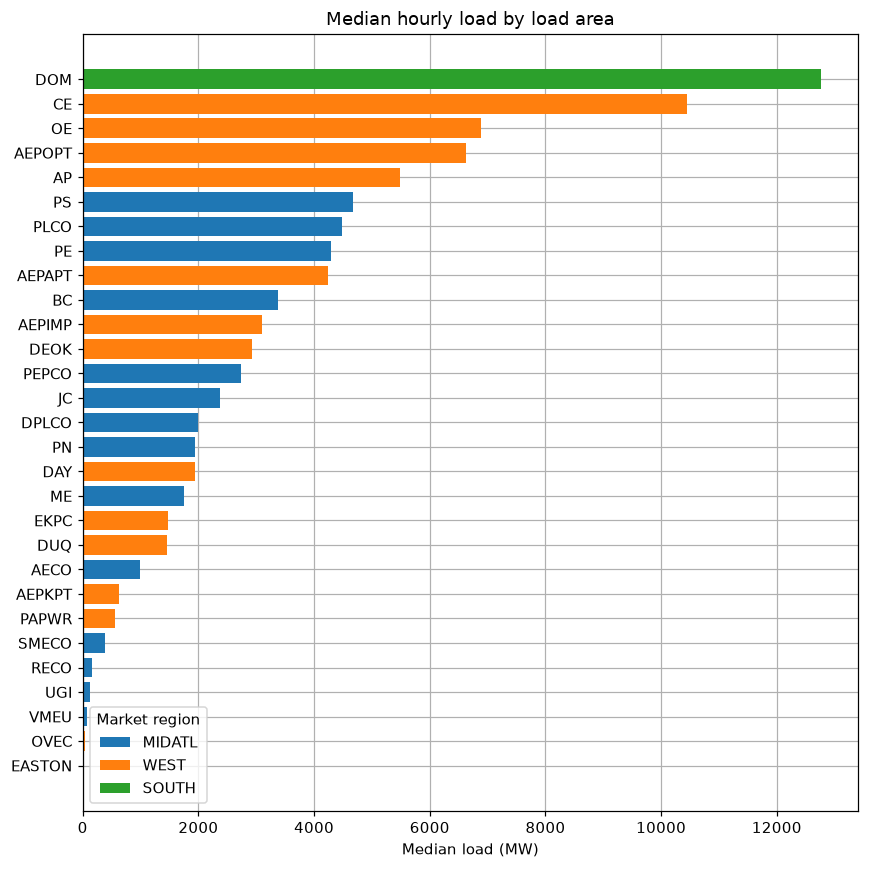

In [7]:
load_summary = (
    load.groupby(["load_area", "zone", "mkt_region"], as_index=False)["load"]
    .agg(hours="count", mean="mean", std="std", min="min", p50="median", max="max")
    .sort_values("p50", ascending=False)
    .reset_index(drop=True)
)
display(load_summary.round(1))

by_size = load_summary.sort_values("p50")
example_areas = [
    by_size["load_area"].iloc[0],
    by_size["load_area"].iloc[len(by_size) // 2],
    by_size["load_area"].iloc[-1],
]
print("shape examples (small, middle, large):", ", ".join(example_areas))

ordered = load_summary.sort_values("p50")
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(
    ordered["load_area"],
    ordered["p50"],
    color=ordered["mkt_region"].map(REGION_COLOR),
)
ax.set_xlabel("Median load (MW)")
ax.set_title("Median hourly load by load area")
ax.legend(
    handles=[Patch(facecolor=color, label=region) for region, color in REGION_COLOR.items()],
    title="Market region",
)
fig.tight_layout()
plt.show()

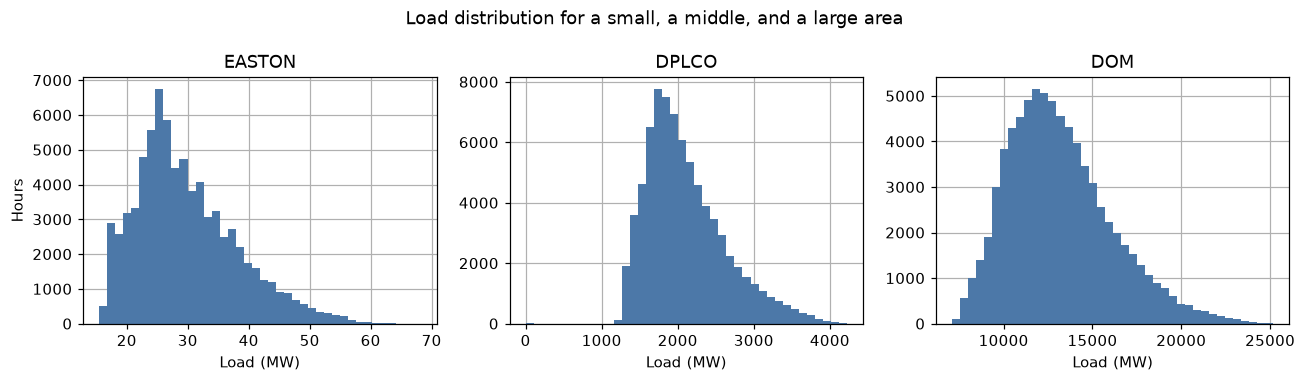

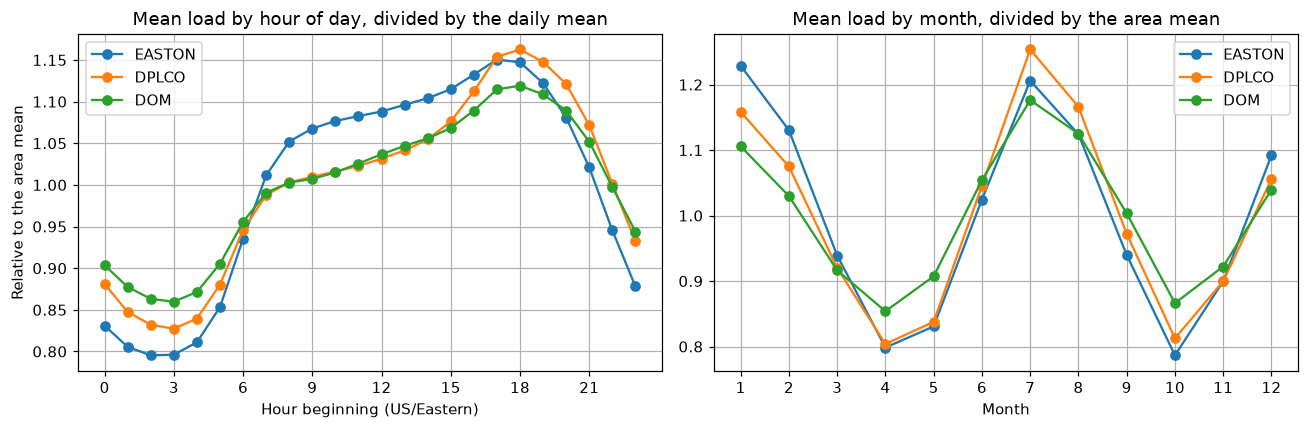

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, area in zip(axes, example_areas):
    values = load.loc[load["load_area"] == area, "load"]
    ax.hist(values, bins=40, color="#4c78a8")
    ax.set_title(area)
    ax.set_xlabel("Load (MW)")
axes[0].set_ylabel("Hours")
fig.suptitle("Load distribution for a small, a middle, and a large area")
fig.tight_layout()
plt.show()

shaped = load.loc[load["load_area"].isin(example_areas)].copy()
shaped["hour"] = shaped["timestamp"].dt.hour
shaped["month"] = shaped["timestamp"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for area in example_areas:
    part = shaped.loc[shaped["load_area"] == area]
    by_hour = part.groupby("hour")["load"].mean()
    by_month = part.groupby("month")["load"].mean()
    axes[0].plot(by_hour.index, by_hour / by_hour.mean(), marker="o", label=area)
    axes[1].plot(by_month.index, by_month / by_month.mean(), marker="o", label=area)
axes[0].set_title("Mean load by hour of day, divided by the daily mean")
axes[0].set_xlabel("Hour beginning (US/Eastern)")
axes[0].set_ylabel("Relative to the area mean")
axes[0].set_xticks(range(0, 24, 3))
axes[0].legend()
axes[1].set_title("Mean load by month, divided by the area mean")
axes[1].set_xlabel("Month")
axes[1].set_xticks(range(1, 13))
axes[1].legend()
fig.tight_layout()
plt.show()

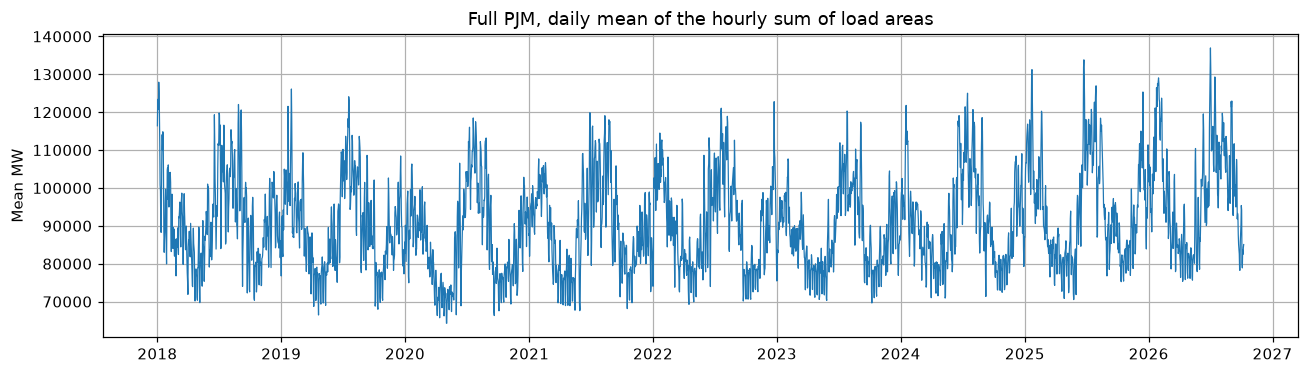

PJM daily mean from 2018-01-01 00:00:00-05:00 to 2026-10-08 00:00:00-04:00, 3203 days


In [9]:
pjm = rollup_load(load, "pjm").set_index("timestamp").sort_index()
daily = pjm["load"].resample("D").mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(daily.index, daily, color="#1f77b4", linewidth=0.8)
ax.set_ylabel("Mean MW")
ax.set_title("Full PJM, daily mean of the hourly sum of load areas")
fig.tight_layout()
plt.show()
print(f"PJM daily mean from {daily.index.min()} to {daily.index.max()}, {len(daily)} days")

### Weather

The histograms pool every load area, so they mix Chicago winters with coastal Mid-Atlantic summers. The monthly means below keep three cities apart: Chicago (`CE`), Richmond (`DOM`), and Atlantic City (`AECO`).

,temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation,surface_pressure
count,2227867.00,2227867.00,2227867.00,2227867.00,2227867.00
mean,12.94,71.02,3.17,173.46,999.67
std,10.27,18.76,1.68,250.84,14.34
min,-32.50,7.00,0.00,0.00,939.80
25%,4.80,57.00,1.97,0.00,988.30
50%,13.70,73.00,2.88,8.00,999.50
75%,21.40,87.00,4.08,302.00,1011.30
max,40.20,100.00,20.26,1023.00,1047.30


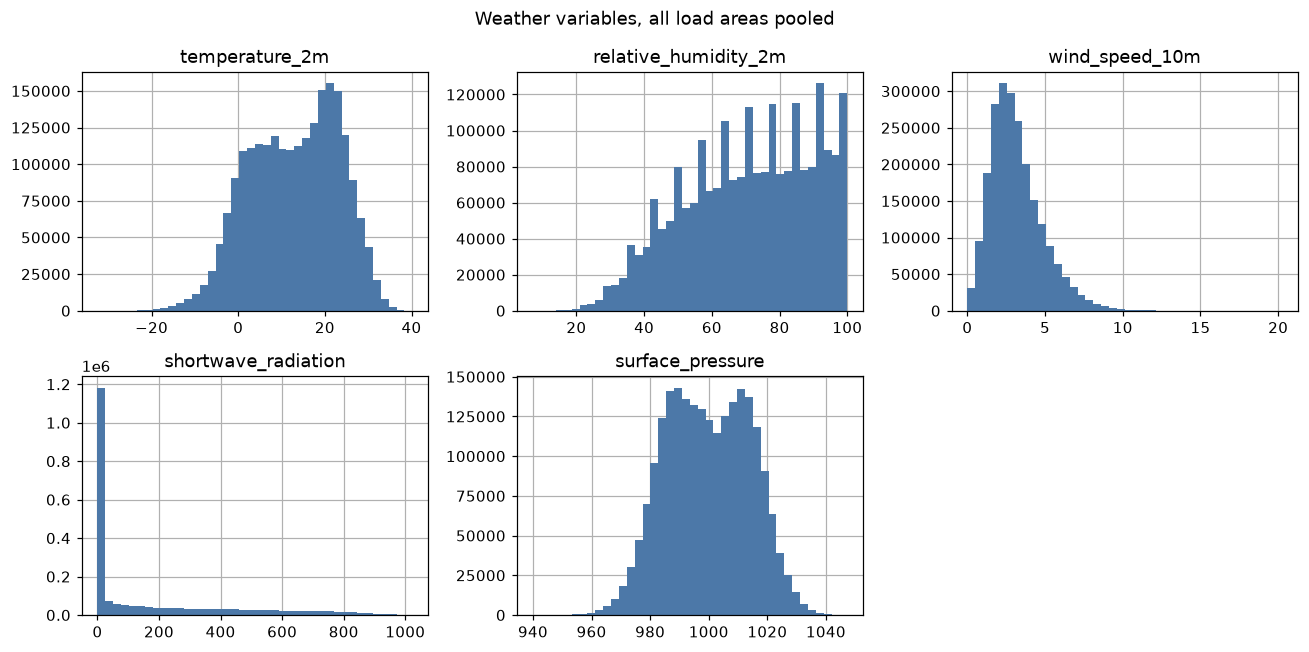

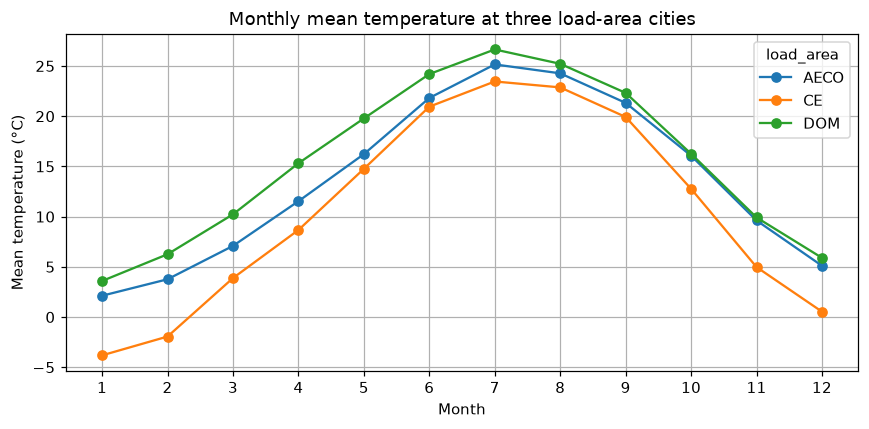

In [10]:
display(weather[list(WEATHER_COLUMNS)].describe().round(2))

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
flat_axes = axes.ravel()
for ax, column in zip(flat_axes, WEATHER_COLUMNS):
    ax.hist(weather[column].dropna(), bins=40, color="#4c78a8")
    ax.set_title(column)
flat_axes[-1].axis("off")
fig.suptitle("Weather variables, all load areas pooled")
fig.tight_layout()
plt.show()

climate_areas = [code for code in ("CE", "DOM", "AECO") if code in set(weather["load_area"])]
climate = weather.loc[weather["load_area"].isin(climate_areas)].copy()
climate["month"] = climate["timestamp"].dt.month
monthly = climate.groupby(["load_area", "month"])["temperature_2m"].mean().unstack("load_area")
fig, ax = plt.subplots(figsize=(8, 4))
monthly.plot(ax=ax, marker="o")
ax.set_ylabel("Mean temperature (°C)")
ax.set_xlabel("Month")
ax.set_xticks(range(1, 13))
ax.set_title("Monthly mean temperature at three load-area cities")
fig.tight_layout()
plt.show()

## 3. Join into `model_df`

`build_load_area_frame` inner-joins the two caches on `timestamp_utc` and `load_area`. An hour that exists in only one cache is left out. Zone and market region come from the load row. The column order is the contract in `FRAME_COLUMNS`.

Training rows and the daily horizon use these same columns. On the horizon, `load` is null and the weather columns come from the forecast API. This notebook builds the training table only.

In [11]:
model_df = build_load_area_frame(load, weather)
print("columns:", list(model_df.columns))
print("matches FRAME_COLUMNS:", list(model_df.columns) == list(FRAME_COLUMNS))
print(f"model_df: {len(model_df):,} rows, {model_df['load_area'].nunique()} load areas")
print("from", model_df["timestamp"].min(), "to", model_df["timestamp"].max())

load_keys = load.loc[:, JOIN_KEYS].drop_duplicates()
weather_keys = weather.loc[:, JOIN_KEYS].drop_duplicates()
audit = load_keys.merge(weather_keys, on=JOIN_KEYS, how="outer", indicator=True)
print("key overlap:")
display(audit["_merge"].value_counts().rename("hours"))

for label, part in audit.groupby("_merge", observed=True):
    print(
        f"{label}: {len(part):,} hours,"
        f" {part['timestamp_utc'].min()} -> {part['timestamp_utc'].max()}"
    )

dropped = (
    audit.loc[audit["_merge"] != "both"]
    .groupby(["load_area", "_merge"], observed=True)
    .size()
    .unstack(fill_value=0)
)
print("hours dropped from either side, by load area (empty means the spans overlap completely):")
display(dropped)

columns: ['timestamp', 'timestamp_utc', 'load_area', 'zone', 'mkt_region', 'load', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'shortwave_radiation', 'surface_pressure']
matches FRAME_COLUMNS: True
model_df: 2,219,831 rows, 29 load areas
from 2018-01-01 00:00:00-05:00 to 2026-10-06 23:00:00-04:00
key overlap:


_merge
both          2219831
right_only       8036
left_only        1392
Name: hours, dtype: int64

left_only: 1,392 hours, 2026-10-07 04:00:00+00:00 -> 2026-10-09 03:00:00+00:00
right_only: 8,036 hours, 2018-01-01 05:00:00+00:00 -> 2026-06-23 09:00:00+00:00
both: 2,219,831 hours, 2018-01-01 05:00:00+00:00 -> 2026-10-07 03:00:00+00:00
hours dropped from either side, by load area (empty means the spans overlap completely):


_merge,left_only,right_only
load_area,,
AECO,48,0
AEPAPT,48,0
AEPIMP,48,0
AEPKPT,48,0
AEPOPT,48,20
AP,48,0
BC,48,0
CE,48,0
DAY,48,0


In [10]:
roles = pd.DataFrame(
    [
        ("timestamp", "US/Eastern hour beginning. OpenSTEF index."),
        ("timestamp_utc", "Join key, together with load_area. Unique instant."),
        ("load_area", "Series id. One model per load area later."),
        ("zone", "Transmission zone. A label; the zone total is a sum of load."),
        ("mkt_region", "MIDATL, WEST, or SOUTH. A label, summed the same way."),
        ("load", "Target, metered MW. Filled on every training row."),
        ("temperature_2m", "Covariate, °C, at that load area's city."),
        ("relative_humidity_2m", "Covariate, %."),
        ("wind_speed_10m", "Covariate, m/s."),
        ("shortwave_radiation", "Covariate, W/m²."),
        ("surface_pressure", "Covariate, hPa."),
    ],
    columns=["column", "role in the forecast"],
)
display(roles)
display(model_df.head(5))
display(model_df.dtypes.to_frame("dtype"))
print("nulls per column:")
display(model_df.isna().sum())
display(model_df["load"].describe().round(1).to_frame("load").T)
display(model_df[list(WEATHER_COLUMNS)].describe().round(2))

repeated_wall = model_df.assign(
    wall=model_df["timestamp"].dt.strftime("%Y-%m-%d %H:%M")
).duplicated(["load_area", "wall"], keep=False)
print(
    "training rows whose Eastern timestamp repeats inside a load area:",
    int(repeated_wall.sum()),
)
print(
    "duplicate (timestamp_utc, load_area) rows:",
    int(model_df.duplicated(JOIN_KEYS).sum()),
)

,column,role in the forecast
0,timestamp,US/Eastern hour beginning. OpenSTEF index.
1,timestamp_utc,"Join key, together with load_area. Unique inst..."
2,load_area,Series id. One model per load area later.
3,zone,Transmission zone. A label; the zone total is ...
4,mkt_region,"MIDATL, WEST, or SOUTH. A label, summed the sa..."
5,load,"Target, metered MW. Filled on every training row."
6,temperature_2m,"Covariate, °C, at that load area's city."
7,relative_humidity_2m,"Covariate, %."
8,wind_speed_10m,"Covariate, m/s."
9,shortwave_radiation,"Covariate, W/m²."


,timestamp,timestamp_utc,load_area,zone,mkt_region,load,temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation,surface_pressure
0,2018-01-01 00:00:00-05:00,2018-01-01 05:00:00+00:00,AECO,AE,MIDATL,1261.317,-11.6,41,5.74,0.0,1027.9
1,2018-01-01 01:00:00-05:00,2018-01-01 06:00:00+00:00,AECO,AE,MIDATL,1221.330,-11.9,42,5.94,0.0,1028.0
2,2018-01-01 02:00:00-05:00,2018-01-01 07:00:00+00:00,AECO,AE,MIDATL,1190.517,-12.1,42,5.80,0.0,1028.4
3,2018-01-01 03:00:00-05:00,2018-01-01 08:00:00+00:00,AECO,AE,MIDATL,1174.050,-12.4,43,5.66,0.0,1028.4
4,2018-01-01 04:00:00-05:00,2018-01-01 09:00:00+00:00,AECO,AE,MIDATL,1168.370,-12.6,44,5.56,0.0,1028.5


,dtype
timestamp,"datetime64[us, US/Eastern]"
timestamp_utc,"datetime64[us, UTC]"
load_area,str
zone,str
mkt_region,str
load,float64
temperature_2m,float64
relative_humidity_2m,int64
wind_speed_10m,float64
shortwave_radiation,float64


nulls per column:


timestamp               0
timestamp_utc           0
load_area               0
zone                    0
mkt_region              0
load                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
shortwave_radiation     0
surface_pressure        0
dtype: int64

,count,mean,std,min,25%,50%,75%,max
load,2219831.0,3148.0,3272.7,0.0,648.6,2211.6,4392.4,25181.0


,temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation,surface_pressure
count,2219831.00,2219831.00,2219831.00,2219831.00,2219831.00
mean,12.94,71.00,3.17,173.46,999.67
std,10.27,18.76,1.68,250.84,14.36
min,-32.50,7.00,0.00,0.00,939.80
25%,4.80,57.00,1.97,0.00,988.30
50%,13.70,73.00,2.88,8.00,999.50
75%,21.40,87.00,4.08,302.00,1011.30
max,40.20,100.00,20.26,1023.00,1047.30


training rows whose Eastern timestamp repeats inside a load area: 462
duplicate (timestamp_utc, load_area) rows: 0


### One series, as the model will see it

Each load area is sliced on its own. The slice below is the largest area by median load. Pearson correlation with temperature is often weak because load rises both when it is cold and when it is hot; the hexbin is the check for that U-shape. A winter week and a summer week show the daily cycle against temperature.

Lags, holidays, and an hour-of-day column are still absent. OpenSTEF derives them from `timestamp` when it trains.

DOM: 76,823 hours, 2018-01-01 00:00:00-05:00 -> 2026-10-06 23:00:00-04:00


,load,temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation,surface_pressure
timestamp,,,,,,
2018-01-01 00:00:00-05:00,16747.941,-8.1,46,3.49,0.0,1023.9
2018-01-01 01:00:00-05:00,16806.026,-8.4,44,3.44,0.0,1023.9
2018-01-01 02:00:00-05:00,16939.452,-8.5,44,3.42,0.0,1023.9
2018-01-01 03:00:00-05:00,17158.701,-8.7,46,3.22,0.0,1024.3
2018-01-01 04:00:00-05:00,17482.735,-8.8,48,3.01,0.0,1024.6
2018-01-01 05:00:00-05:00,17916.559,-8.9,50,2.83,0.0,1024.8
2018-01-01 06:00:00-05:00,18244.035,-9.0,52,2.77,0.0,1025.1
2018-01-01 07:00:00-05:00,18475.872,-9.1,54,3.10,0.0,1026.1


,load,temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation,surface_pressure
load,1.00,0.13,-0.21,-0.08,0.25,0.03
temperature_2m,0.13,1.00,-0.07,-0.07,0.43,-0.35
relative_humidity_2m,-0.21,-0.07,1.00,-0.19,-0.60,-0.10
wind_speed_10m,-0.08,-0.07,-0.19,1.00,0.04,-0.29
shortwave_radiation,0.25,0.43,-0.60,0.04,1.00,-0.01
surface_pressure,0.03,-0.35,-0.10,-0.29,-0.01,1.00


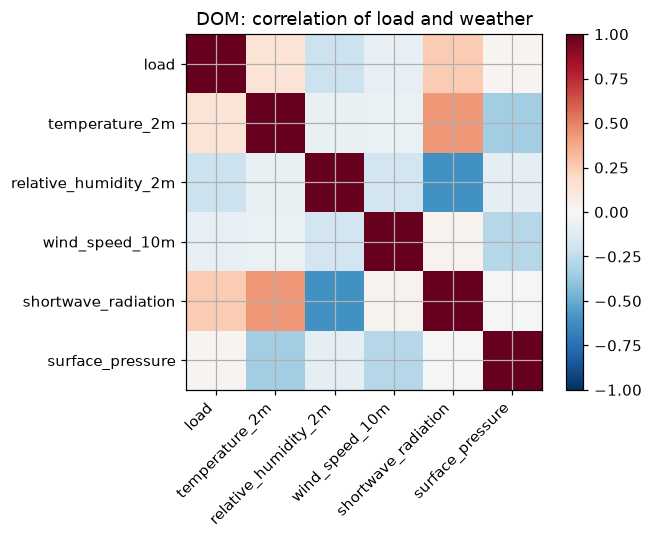

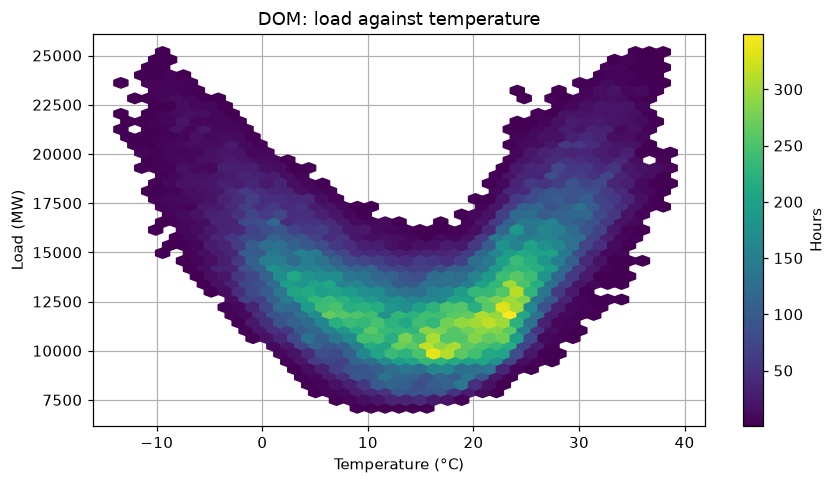

In [12]:
focus = example_areas[-1]
series = (
    model_df.loc[model_df["load_area"] == focus]
    .sort_values("timestamp_utc")
    .set_index("timestamp")
)
print(f"{focus}: {len(series):,} hours, {series.index.min()} -> {series.index.max()}")
display(series[["load", *WEATHER_COLUMNS]].head(8))

feature_cols = ["load", *WEATHER_COLUMNS]
corr = series[feature_cols].corr(numeric_only=True)
display(corr.round(2))

fig, ax = plt.subplots(figsize=(6.2, 5))
image = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)), feature_cols, rotation=45, ha="right")
ax.set_yticks(range(len(feature_cols)), feature_cols)
ax.set_title(f"{focus}: correlation of load and weather")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = ax.hexbin(
    series["temperature_2m"],
    series["load"],
    gridsize=40,
    cmap="viridis",
    mincnt=1,
)
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Load (MW)")
ax.set_title(f"{focus}: load against temperature")
fig.colorbar(bins, ax=ax, label="Hours")
fig.tight_layout()
plt.show()

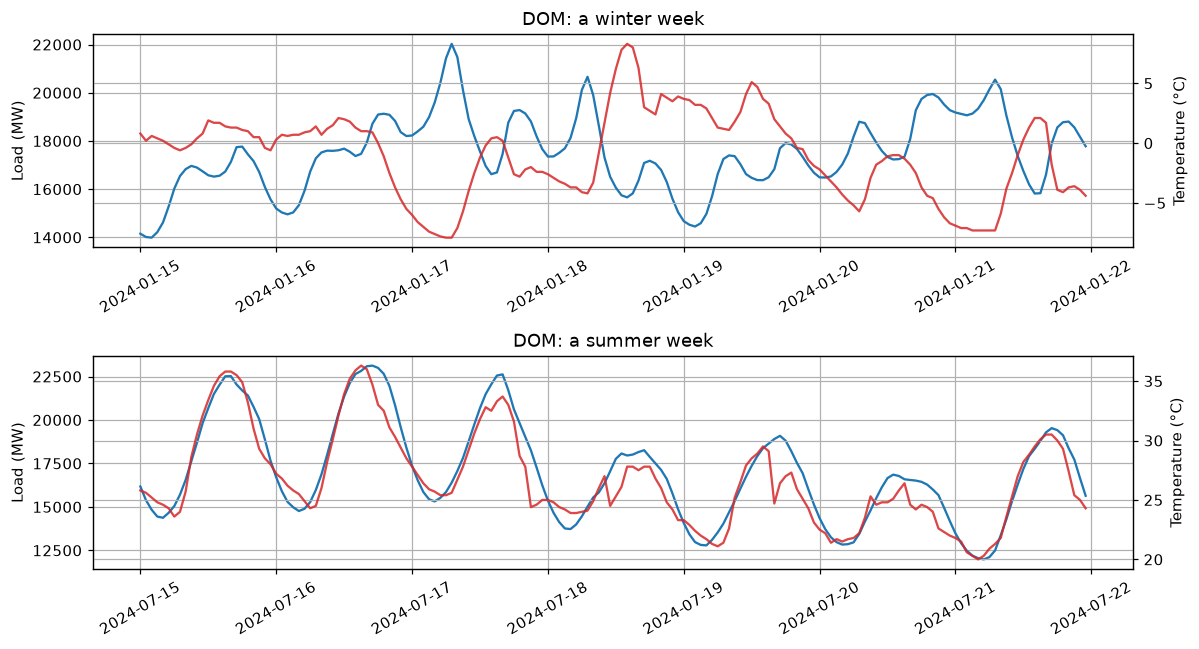

In [13]:
def plot_week(ax, start: str, title: str) -> None:
    start_ts = pd.Timestamp(start, tz="US/Eastern")
    end_ts = start_ts + pd.Timedelta(days=7)
    week = series.loc[(series.index >= start_ts) & (series.index < end_ts)]
    ax.plot(week.index, week["load"], color="#1f77b4", label="load")
    ax.set_ylabel("Load (MW)")
    ax.set_title(title)
    twin = ax.twinx()
    twin.plot(week.index, week["temperature_2m"], color="#d62728", alpha=0.85, label="temperature")
    twin.set_ylabel("Temperature (°C)")
    ax.tick_params(axis="x", labelrotation=30)

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
plot_week(axes[0], "2024-01-15", f"{focus}: a winter week")
plot_week(axes[1], "2024-07-15", f"{focus}: a summer week")
fig.tight_layout()
plt.show()

## What goes into the model

`model_df` is long: one row per load area per hour, restricted to hours present in both caches. A training run will split it by `load_area`. For each series the index is `timestamp` and the target is `load`. The five weather columns are covariates known for that hour. `zone` and `mkt_region` identify the series; a zone, region, or full-PJM forecast is the sum of the load-area forecasts, so those totals are not extra targets in this table.

The inner join drops the ragged edge where one cache runs past the other. Inside the overlap, a gap in either source removes that hour for that load area.

Once a year the US/Eastern wall clock repeats. Both instants remain, with the same `timestamp` and different `timestamp_utc` values. The join key is the UTC instant, so both hours are kept.